# Predicción de hipoglucemia asociada al ejercicio en personas con diabetes

## Proyecto de Aprendizaje Automático

### Descripción del proyecto

En este proyecto voy a investigar si es posible anticipar episodios de hipoglucemia en personas con diabetes a partir de los niveles de glucosa y la intensidad de la actividad física.

Para realizar el análisis utilizo el dataset **CGMacros**, que contiene registros de glucosa y actividad física obtenidos mediante dispositivos de monitoreo.

Mi objetivo es desarrollar un modelo de **regresión logística** que permita estimar la probabilidad de que ocurra un episodio de hipoglucemia.

### Pregunta de investigación

¿Puedo clasificar ventanas según el inicio de un episodio de hipoglucemia durante los próximos 60 minutos utilizando la glucosa media y la actividad física registradas durante los 60 minutos anteriores?

### Definiciones utilizadas

- **Hipoglucemia:** considero una glucosa inferior a 70 mg/dL.
- **Episodio de hipoglucemia:** establezco como criterio al menos 15 mediciones consecutivas, realizadas cada minuto, con glucosa inferior a 70 mg/dL.
- **MET:** utilizo esta medida para expresar la intensidad de la actividad física.
- **HbA1c:** utilizo un valor superior al 6,4 % como criterio de selección de los participantes.

### Alcance del proyecto

Con este análisis busco identificar asociaciones entre las variables y evaluar la capacidad predictiva del modelo. Los resultados no permiten establecer relaciones de causalidad ni realizar recomendaciones clínicas individuales.

## Descripción del dataset CGMacros

### Origen de los datos

El dataset **CGMacros (Continuous Glucose Monitoring and Macronutrients)** fue desarrollado por investigadores vinculados a Texas A&M University y al Sansum Diabetes Research Institute, ubicado en Santa Bárbara, California, Estados Unidos.

Los participantes fueron reclutados entre 2021 y 2024. El conjunto de datos fue publicado en PhysioNet en enero de 2025 y posteriormente descrito en la revista científica *Scientific Data*.

El objetivo original del estudio fue investigar las relaciones entre alimentación, glucosa, actividad física y características metabólicas, para contribuir al desarrollo de herramientas de nutrición personalizada.

**Fuente:** https://physionet.org/content/cgmacros/1.0.0/

### Características de la población

El estudio original incluyó **45 participantes adultos**, distribuidos de la siguiente manera:

- 15 personas sin diabetes.
- 16 personas con prediabetes.
- 14 personas con diabetes mellitus tipo 2.

Las edades estuvieron comprendidas entre 18 y 69 años.

Los participantes fueron estudiados durante aproximadamente 10 días consecutivos, mientras realizaban sus actividades habituales.

### Obtención de los datos

Se utilizaron diferentes dispositivos y procedimientos:

- **Monitores continuos de glucosa:** Abbott FreeStyle Libre Pro y Dexcom G6 Pro, para registrar los niveles de glucosa.
- **Reloj Fitbit Sense:** para registrar la actividad física y la frecuencia cardíaca.
- **Registros alimentarios:** para documentar comidas, calorías y macronutrientes.
- **Análisis de laboratorio:** para obtener información metabólica, incluida la hemoglobina glucosilada (HbA1c).

Los registros de glucosa fueron procesados por los investigadores originales mediante interpolación para disponer de valores a intervalos de un minuto.

### Organización del dataset

El conjunto original contiene 45 archivos CSV individuales, correspondientes a los participantes, y archivos complementarios con información clínica y biológica.

Entre los archivos utilizados en este proyecto se encuentran:

**bio.csv**

Contiene información de los participantes, incluyendo datos demográficos, antropométricos y resultados de laboratorio. En este trabajo se utiliza principalmente para seleccionar participantes con HbA1c superior al 6,4 %, según el criterio definido para este análisis.

**CGMacros-XXX.csv**

Contienen los registros temporales individuales de glucosa, actividad física y otras mediciones.

Estos archivos permiten analizar cómo varían las mediciones a lo largo del tiempo y estudiar su relación con la aparición de hipoglucemia.

### Utilización del dataset en este proyecto

A diferencia del objetivo original de CGMacros, centrado en la nutrición personalizada, este proyecto utiliza los registros para investigar la **predicción de episodios de hipoglucemia mediante aprendizaje automático**.

Se seleccionan 14 participantes con HbA1c superior al 6,4 %, de acuerdo con el criterio aplicado en el código.

Las principales variables consideradas son:

- **Glucosa previa:** información de los niveles de glucosa registrados durante los 60 minutos anteriores.
- **Actividad física previa:** información de la intensidad de actividad física, expresada mediante MET, durante los 60 minutos anteriores.
- **Hipoglucemia:** variable objetivo que identifica el inicio de un episodio con glucosa inferior a 70 mg/dL, mantenida durante al menos 15 registros consecutivos de un minuto.

Se construyen ventanas temporales para utilizar la información anterior al período que se desea predecir.

El objetivo es estimar la probabilidad de que comience un episodio de hipoglucemia durante los siguientes 60 minutos.

Para ello se utiliza un modelo de **regresión logística**, que permite estudiar la relación entre las variables predictoras y la aparición de hipoglucemia.

### Referencias

Gutierrez-Osuna, R., Kerr, D., Mortazavi, B. y Das, A. (2025). *CGMacros: a scientific dataset for personalized nutrition and diet monitoring*. PhysioNet, versión 1.0.0.

https://doi.org/10.13026/3z8q-x658

Das, A. y colaboradores (2025). *CGMacros: a pilot scientific dataset for personalized nutrition and diet monitoring*. Scientific Data.

https://doi.org/10.1038/s41597-025-05851-7

## 1. Importación de bibliotecas y selección de participantes

En esta primera etapa importo las bibliotecas de Python que necesito para trabajar con los datos.

- **Pandas:** para leer y organizar los datos.
- **NumPy:** para realizar operaciones numéricas.
- **Matplotlib:** para crear gráficos.
- **Scikit-learn:** para preparar los datos, entrenar el modelo de regresión logística y evaluar sus resultados.
- **Pathlib:** para localizar los archivos del proyecto.

### Selección de participantes

Primero localizo los archivos del dataset CGMacros y leo el archivo `bio.csv`, que contiene información de los participantes.

Después selecciono a las personas que tienen una hemoglobina glucosilada (HbA1c) superior al 6,4 %, según el criterio establecido para mi análisis.

**Resultado:** obtengo 14 participantes que cumplen este criterio.

Finalmente, verifico que la cantidad de participantes seleccionados sea la esperada.

Estos participantes serán la base para continuar con el análisis de glucosa, actividad física e hipoglucemia.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score, roc_auc_score

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data'/'bio.csv').is_file() and (p/'data'/'CGMacros_14_CSV_GitHub').is_dir()), None)
if raiz is None:
    raise FileNotFoundError('Descargá el repositorio completo y ejecutá desde su raíz o desde notebooks/. Deben existir data/bio.csv y data/CGMacros_14_CSV_GitHub/.')
carpeta = raiz/'data'/'CGMacros_14_CSV_GitHub'
bio = pd.read_csv(raiz/'data'/'bio.csv')
seleccion = bio.loc[bio['A1c PDL (Lab)'] > 6.4, 'subject'].astype(int).tolist()
print('Participantes seleccionados por HbA1c:', len(seleccion), seleccion)
assert len(seleccion)==14, 'Revisar la selección de participantes: no coincide con los 14 esperados.' 

Participantes seleccionados por HbA1c: 14 [3, 5, 12, 14, 28, 30, 35, 36, 38, 39, 42, 46, 47, 49]


## 2. Control de calidad y disponibilidad de variables

Antes de comenzar el análisis, necesito comprobar que los datos sean adecuados para trabajar con ellos.

Para eso, reviso los archivos correspondientes a cada uno de los 14 participantes seleccionados.

Realizo las siguientes comprobaciones:

- **Cantidad de registros:** verifico cuántas mediciones tiene cada participante.
- **Fechas y horarios:** compruebo que los registros tengan fechas válidas y estén ordenados cronológicamente.
- **Datos duplicados:** elimino los registros repetidos, conservando la primera medición.
- **Valores faltantes:** identifico si existen datos ausentes.
- **Variables disponibles:** compruebo que estén presentes las variables necesarias para estudiar la glucosa y la actividad física.

No completo los valores faltantes mediante interpolación y evito utilizar información futura para realizar las predicciones.

**Objetivo:** asegurar que los datos tengan la calidad necesaria antes de construir el modelo de aprendizaje automático.

In [2]:
datos = {}
auditoria = []
for pid in seleccion:
    nombre = f'CGMacros-{pid:03d}'
    archivo = carpeta/f'{nombre}.csv'
    if not archivo.is_file():
        raise FileNotFoundError(f'No está {archivo}')
    df = pd.read_csv(archivo)
    filas_originales = len(df)
    if not {'Timestamp','Libre GL'}.issubset(df.columns):
        raise ValueError(f'Faltan Timestamp o Libre GL en {nombre}')
    df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
    invalidas = int(df['Timestamp'].isna().sum())
    df = df.dropna(subset=['Timestamp']).sort_values('Timestamp')
    duplicados = int(df['Timestamp'].duplicated().sum())
    df = df.drop_duplicates('Timestamp', keep='first').reset_index(drop=True)
    tiene_met = 'METs' in df.columns
    auditoria.append({'Participante':nombre,'Filas originales':filas_originales,'Fechas inválidas':invalidas,'Duplicados':duplicados,'Faltantes glucosa':int(df['Libre GL'].isna().sum()),'Tiene METs':tiene_met,'Faltantes METs':int(df['METs'].isna().sum()) if tiene_met else np.nan,'Filas tras limpieza':len(df)})
    if tiene_met:
        datos[nombre] = df
calidad = pd.DataFrame(auditoria)
print(calidad.to_string(index=False))
print('Total de registros originales:',calidad['Filas originales'].sum())
print('Participantes sin METs:',calidad.loc[~calidad['Tiene METs'],'Participante'].tolist())
print('Participantes con ambas variables:',len(datos))

Participante  Filas originales  Fechas inválidas  Duplicados  Faltantes glucosa  Tiene METs  Faltantes METs  Filas tras limpieza
CGMacros-003             14565                 0           0                  0        True             0.0                14565
CGMacros-005             14460                 0           0                  0        True            22.0                14460
CGMacros-012             14655                 0           0                  0        True             0.0                14655
CGMacros-014             17250                 0           0                  0        True          1951.0                17250
CGMacros-028             18735                 0           0                  0        True          3379.0                18735
CGMacros-030             15465                 0           0                  0        True          1632.0                15465
CGMacros-035             14400                 0           0                  0       False      

### Resultados del control de calidad

Al revisar los datos de los 14 participantes, obtengo un total de **218.535 registros originales**.

Compruebo que no existen fechas inválidas, registros duplicados ni valores faltantes de glucosa.

Sin embargo, encuentro que cuatro participantes (035, 038, 042 y 046) no tienen registros de actividad física expresados en MET.

Por lo tanto, **10 participantes disponen de ambas variables**, aunque algunos presentan mediciones faltantes de MET.

Este control es importante porque me permite conocer la calidad y disponibilidad de los datos antes de construir las variables que utilizaré en el modelo predictivo.

## 3. Construcción prospectiva de ventanas

Para **no seleccionar casos positivos a partir del inicio ya conocido del episodio**, se crean ventanas fijas, no solapadas, de 120 registros consecutivos por participante, comenzando desde su primer registro. La primera hora es observación y la segunda es el horizonte de predicción. Solo se usan glucosa y METs de la primera hora como predictores.

- **Positivo (1):** observación sin hipoglucemia y comienzo de al menos un episodio válido de 15 registros consecutivos bajo 70 durante la hora futura; el episodio debe poder confirmarse dentro de esa hora.
- **Negativo (0):** observación sin hipoglucemia y ninguna lectura bajo 70 durante la hora futura.
- **Indeterminado:** aparece alguna lectura bajo 70 en el futuro, pero no se confirma un episodio válido completo; se excluye **de ambas clases**, con recuento explícito.

Se descartan ventanas con interrupciones temporales o faltantes en cualquiera de las dos horas, y aquellas con hipoglucemia ya presente en la observación. Se exige información futura completa únicamente para construir la etiqueta retrospectivamente; nunca se utiliza para los predictores. El muestreo fijo puede omitir episodios que caen entre ventanas y constituye una limitación del estudio.

### Cálculo de las ventanas

Para construir las ventanas, divido los registros de cada participante en bloques consecutivos de **120 mediciones**, que deben estar separadas por intervalos de un minuto.

Cada bloque representa 2 horas:

- **Primera hora (60 mediciones):** calculo el promedio de glucosa y el promedio de actividad física (METs, dividido por 10 según el procesamiento del código). Estas son las dos variables que utilizaré para predecir.
- **Segunda hora (60 mediciones):** verifico si comienza un episodio válido de hipoglucemia.

Las ventanas no se superponen. Por ejemplo:

- Ventana 1: minutos 0 a 119.
- Ventana 2: minutos 120 a 239.
- Ventana 3: minutos 240 a 359.

Para calcular la cantidad inicial de ventanas, divido los registros de cada participante por 120 y considero solamente los bloques completos.

Luego sumo las ventanas obtenidas de todos los participantes.

**Resultado:** obtengo 1.332 ventanas candidatas. Después de aplicar los criterios de exclusión, quedan 1.213 ventanas válidas para el análisis.

In [3]:
filas=[]
controles=[]
for nombre,df in datos.items():
    n_total=n_validas=n_sin_cont=n_falt=n_hipo_pre=n_indet=0
    positivos=negativos=0
    for inicio in range(0,len(df)-119,120):
        n_total+=1
        w=df.iloc[inicio:inicio+120]
        if not w['Timestamp'].diff().iloc[1:].eq(pd.Timedelta(minutes=1)).all():
            n_sin_cont+=1; continue
        if w[['Libre GL','METs']].isna().any().any():
            n_falt+=1; continue
        obs=w.iloc[:60]; futuro=w.iloc[60:]
        if (obs['Libre GL']<70).any():
            n_hipo_pre+=1;continue
        bajos=futuro['Libre GL'].lt(70).to_numpy()
        inicios=np.flatnonzero(bajos & ~np.r_[False,bajos[:-1]])
        episodio_valido=any(i+15<=60 and bajos[i:i+15].all() for i in inicios)
        if episodio_valido:
            etiqueta=1; positivos+=1
        elif not bajos.any():
            etiqueta=0; negativos+=1
        else:
            n_indet+=1;continue
        filas.append({'Participante':nombre,'Inicio_observacion':obs['Timestamp'].iloc[0], 'Fin_observacion':obs['Timestamp'].iloc[-1], 'Inicio_prediccion':futuro['Timestamp'].iloc[0], 'Fin_prediccion':futuro['Timestamp'].iloc[-1], 'Glucosa_media':obs['Libre GL'].mean(), 'MET_medio':obs['METs'].mean()/10, 'Hipoglucemia':etiqueta})
    controles.append({'Participante':nombre,'Ventanas candidatas':n_total,'Sin continuidad':n_sin_cont,'Con faltantes':n_falt,'Hipoglucemia previa':n_hipo_pre,'Futuro indeterminado':n_indet,'Positivas':positivos,'Negativas':negativos})
control=pd.DataFrame(controles)
ventanas=pd.DataFrame(filas)
print(control.to_string(index=False))
print('TOTALES:',control.select_dtypes(include='number').sum().to_string())
print('Distribución de etiquetas:',ventanas.Hipoglucemia.value_counts().to_dict())
print('Participantes con positivos:',ventanas.loc[ventanas.Hipoglucemia.eq(1),'Participante'].nunique())
assert not ventanas.empty and ventanas.Hipoglucemia.nunique()==2
assert ventanas[['Glucosa_media','MET_medio']].notna().all().all()

Participante  Ventanas candidatas  Sin continuidad  Con faltantes  Hipoglucemia previa  Futuro indeterminado  Positivas  Negativas
CGMacros-003                  121                1              0                    5                     0          1        114
CGMacros-005                  120                0              0                    3                     0          2        115
CGMacros-012                  122                1              0                    0                     0          0        121
CGMacros-014                  143                0             16                    1                     1          0        125
CGMacros-028                  156                0             29                    2                     0          1        124
CGMacros-030                  128                0             13                    1                     0          0        114
CGMacros-036                  142                0             15                  

### Resultados de la construcción de ventanas

Inicialmente obtengo **1.332 ventanas candidatas** correspondientes a los 10 participantes con datos de glucosa y actividad física.

Durante el procesamiento descarto:

- 2 ventanas por interrupciones temporales.
- 73 ventanas por valores faltantes.
- 42 ventanas porque ya existía hipoglucemia durante la primera hora.
- 2 ventanas porque no se pudo confirmar un episodio válido de hipoglucemia.

Finalmente obtengo **1.213 ventanas válidas**, clasificadas en:

- **12 positivas:** presentan un episodio válido de hipoglucemia.
- **1.201 negativas:** no presentan hipoglucemia.

Los 12 casos positivos corresponden a 6 participantes diferentes.

### Interpretación de los resultados

Observo un importante **desbalance entre las clases**: el 99,01 % de las ventanas son negativas y solamente el 0,99 % son positivas.

Esto representa una dificultad para el aprendizaje automático, porque el modelo podría obtener una exactitud elevada prediciendo siempre la ausencia de hipoglucemia.

Por este motivo, considero necesario evaluar especialmente su capacidad para detectar los episodios de hipoglucemia, además de la exactitud general.

La escasa cantidad de casos positivos constituye una limitación importante de mi estudio.

## 4. Exploración descriptiva

En esta etapa analizo cómo se distribuyen los valores de glucosa media y actividad física (MET medio (METs/10)) en las ventanas con y sin hipoglucemia.

Para cada grupo calculo:

- **Cantidad:** número de ventanas.
- **Media:** promedio de los valores.
- **Mediana:** valor central de los datos ordenados.

También utilizo diagramas de caja (boxplots) para comparar la distribución de ambas variables entre los dos grupos.

Mi objetivo es observar si existen diferencias en los niveles de glucosa previa y actividad física entre las ventanas que presentan hipoglucemia y las que no.

Cada ventana representa un período de observación de un participante, no una persona diferente.

Este análisis permite describir posibles asociaciones, pero no demuestra que la actividad física sea la causa de la hipoglucemia.

             Glucosa_media                 MET_medio             
                     count    mean  median     count  mean median
Hipoglucemia                                                     
0                     1201  133.41  122.40      1201  1.77   1.44
1                       12   95.51   86.96        12  1.59   1.32


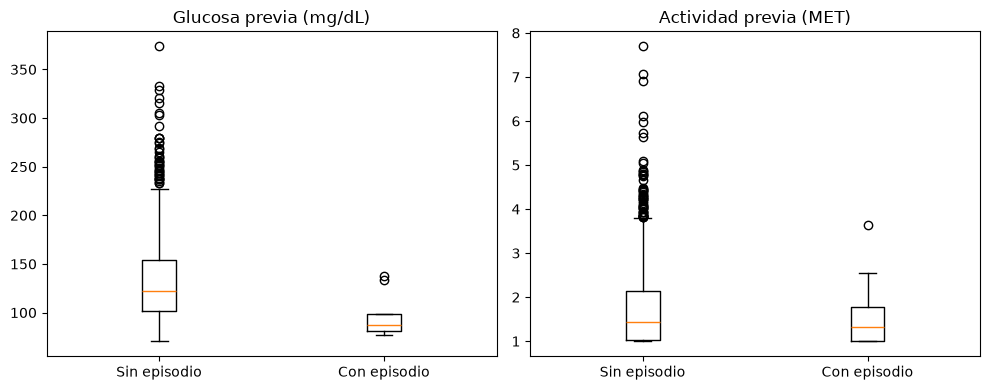

In [4]:
print(ventanas.groupby('Hipoglucemia')[['Glucosa_media','MET_medio']].agg(['count','mean','median']).round(2).to_string())
fig,axs=plt.subplots(1,2,figsize=(10,4))
for ax,var,titulo in zip(axs,['Glucosa_media','MET_medio'],['Glucosa previa (mg/dL)','Actividad previa (MET)']):
    grupos=[ventanas.loc[ventanas.Hipoglucemia.eq(i),var] for i in [0,1]]
    ax.boxplot(grupos,tick_labels=['Sin episodio','Con episodio']);ax.set_title(titulo)
plt.tight_layout();plt.show()

### Resultados de la exploración descriptiva

**1. Glucosa previa**

Al comparar los dos grupos, observo que:

- **Sin hipoglucemia:** la glucosa media es de 133,41 mg/dL y la mediana de 122,40 mg/dL.
- **Con hipoglucemia:** la glucosa media es de 95,51 mg/dL y la mediana de 86,96 mg/dL.

Esto indica que las ventanas en las que posteriormente comienza una hipoglucemia presentan, en promedio, valores de glucosa previa más bajos.

En el primer diagrama de caja también observo una menor dispersión de los valores de glucosa en el grupo con hipoglucemia.

**2. Actividad física previa (METs/10)**

Al analizar la intensidad de la actividad física encuentro:

- **Sin hipoglucemia:** MET medio de 1,77 y mediana de 1,44.
- **Con hipoglucemia:** MET medio de 1,59 y mediana de 1,32.

Los valores son relativamente similares, aunque ligeramente menores en las ventanas con hipoglucemia.

El segundo diagrama de caja muestra una importante superposición entre ambos grupos.

### Interpretación general

En esta muestra, la glucosa previa presenta una diferencia descriptiva más marcada entre las ventanas con y sin hipoglucemia que la actividad física.

Sin embargo, estos resultados no demuestran que una variable sea mejor predictora que la otra. Para evaluarlo necesito analizar el comportamiento del modelo de regresión logística.

Además, debo interpretar los resultados con precaución porque solamente dispongo de **12 ventanas positivas**, correspondientes a 6 participantes.

Estos resultados describen asociaciones observadas y no permiten establecer relaciones de causalidad.

## 5. Entrenamiento y prueba por participante

En esta etapa preparo los datos para entrenar y evaluar mi modelo de regresión logística.

### Separación de entrenamiento y prueba

Divido los datos en dos conjuntos:

- **Entrenamiento (70 % aproximadamente):** utilizo estos datos para que el modelo aprenda a identificar patrones relacionados con la hipoglucemia.
- **Prueba (30 % aproximadamente):** reservo estos datos para evaluar el modelo con información que no utilizó durante el entrenamiento.

Realizo la separación por participante utilizando `GroupShuffleSplit`. De esta manera, las ventanas de una misma persona nunca aparecen en ambos conjuntos.

También busco una división que contenga al menos tres ventanas positivas en cada conjunto. Reconozco que seleccionar la división según la presencia de casos positivos es una limitación metodológica, aunque no utilizo el rendimiento del modelo para elegirla.

### Balanceo de las clases

Como existen muchas más ventanas sin hipoglucemia que con hipoglucemia, realizo un submuestreo aleatorio de la clase mayoritaria.

Conservo todos los casos positivos de entrenamiento y selecciono la misma cantidad de negativos.

**Aplico el balanceo solamente al conjunto de entrenamiento.** El conjunto de prueba mantiene su distribución original para evaluar el modelo en condiciones más representativas de los datos disponibles.

### Escalado de las variables

Utilizo `StandardScaler` para estandarizar las dos variables predictoras:

- Glucosa media.
- MET medio (columna METs dividida por 10).

Calculo los parámetros del escalado utilizando únicamente los datos de entrenamiento balanceados y después aplico esa misma transformación al conjunto de prueba.

Esto evita utilizar información del conjunto de prueba durante la preparación del modelo.

### Entrenamiento del modelo

Finalmente, utilizo una **regresión logística**, un algoritmo de clasificación que estima la probabilidad de pertenecer a una de dos clases:

- **0:** sin hipoglucemia.
- **1:** con hipoglucemia.

Configuro un máximo de 1.000 iteraciones para el ajuste del modelo.

In [5]:
opciones=[]
for semilla in range(100):
    gss=GroupShuffleSplit(n_splits=1,test_size=.3,random_state=semilla)
    it,iv=next(gss.split(ventanas,groups=ventanas.Participante))
    a,b=ventanas.iloc[it],ventanas.iloc[iv]
    if a.Hipoglucemia.sum()>=3 and b.Hipoglucemia.sum()>=3:
        opciones.append((semilla,it,iv));break
if not opciones:
    raise ValueError('No es posible formar conjuntos con al menos tres positivos por grupo.')
semilla,it,iv=opciones[0]
train=ventanas.iloc[it].copy();test=ventanas.iloc[iv].copy()
assert set(train.Participante).isdisjoint(test.Participante)
print('Semilla de separación:',semilla)
print('Participantes de entrenamiento:',sorted(train.Participante.unique()))
print('Participantes de prueba:',sorted(test.Participante.unique()))
print('Clases entrenamiento:',train.Hipoglucemia.value_counts().to_dict())
print('Clases prueba:',test.Hipoglucemia.value_counts().to_dict())
pos=train[train.Hipoglucemia.eq(1)]
neg=train[train.Hipoglucemia.eq(0)].sample(n=len(pos),random_state=42)
train_balanceado=pd.concat([pos,neg],ignore_index=True).sample(frac=1,random_state=42)
variables=['Glucosa_media','MET_medio']
scaler=StandardScaler()
X_train=scaler.fit_transform(train_balanceado[variables]);X_test=scaler.transform(test[variables])
y_train=train_balanceado.Hipoglucemia;y_test=test.Hipoglucemia
modelo=LogisticRegression(max_iter=1000,random_state=42)
modelo.fit(X_train,y_train)
print('Entrenamiento balanceado:',y_train.value_counts().to_dict())

Semilla de separación: 1
Participantes de entrenamiento: ['CGMacros-003', 'CGMacros-005', 'CGMacros-014', 'CGMacros-028', 'CGMacros-030', 'CGMacros-039', 'CGMacros-047']
Participantes de prueba: ['CGMacros-012', 'CGMacros-036', 'CGMacros-049']
Clases entrenamiento: {0: 861, 1: 6}
Clases prueba: {0: 340, 1: 6}
Entrenamiento balanceado: {0: 6, 1: 6}


### Resultados del entrenamiento

La separación seleccionada utiliza 7 participantes para entrenamiento y 3 para prueba.

**Conjunto de entrenamiento:**

- 861 ventanas sin hipoglucemia.
- 6 ventanas con hipoglucemia.
- Total: 867 ventanas.

**Conjunto de prueba:**

- 340 ventanas sin hipoglucemia.
- 6 ventanas con hipoglucemia.
- Total: 346 ventanas.

### Resultado del balanceo

Para entrenar el modelo con clases equilibradas, conservo las 6 ventanas positivas y selecciono aleatoriamente 6 negativas.

De esta manera, el entrenamiento se realiza con **12 ventanas: 6 positivas y 6 negativas**.

El conjunto de prueba conserva sus 346 ventanas originales, sin balanceo.

### Interpretación

La separación por participante evita que el modelo sea evaluado con registros de personas que ya utilizó durante el entrenamiento.

El balanceo impide que la clase mayoritaria domine el conjunto de entrenamiento.

Sin embargo, reconozco una limitación importante: el modelo se entrena con solamente 12 ventanas y se evalúa con 6 ventanas positivas.

Por lo tanto, sus resultados pueden ser inestables y no permiten afirmar que tenga capacidad predictiva generalizable a otros pacientes.

## 6. Evaluación en participantes de prueba

En esta etapa evalúo el funcionamiento de mi modelo de regresión logística utilizando los datos de los 3 participantes reservados para prueba.

Estos participantes no fueron utilizados durante el entrenamiento.

Para evaluar el modelo utilizo las siguientes métricas:

- **Exactitud (accuracy):** porcentaje total de predicciones correctas.
- **Exactitud balanceada:** promedio de la sensibilidad de ambas clases, para tener en cuenta el desbalance.
- **Sensibilidad (recall):** proporción de ventanas positivas que el modelo consigue identificar.
- **Precisión (precision):** proporción de predicciones positivas que realmente corresponden a hipoglucemia.
- **F1-score:** medida que combina precisión y sensibilidad.
- **ROC-AUC:** mide la capacidad del modelo para distinguir entre ventanas con y sin hipoglucemia utilizando diferentes umbrales de clasificación.
- **Matriz de confusión:** permite conocer los aciertos y errores de clasificación.

Mi objetivo es comprobar si el modelo consigue identificar ventanas con hipoglucemia en participantes que no utilizó durante el entrenamiento.

In [6]:
pred_train=modelo.predict(X_train)
pred_test=modelo.predict(X_test)
proba=modelo.predict_proba(X_test)[:,1]
tn,fp,fn,tp=confusion_matrix(y_test,pred_test,labels=[0,1]).ravel()
print('Exactitud entrenamiento balanceado:',round(accuracy_score(y_train,pred_train),3))
print('Exactitud prueba:',round(accuracy_score(y_test,pred_test),3))
print('Exactitud balanceada prueba:',round(balanced_accuracy_score(y_test,pred_test),3))
print('ROC-AUC prueba:',round(roc_auc_score(y_test,proba),3))
print('Matriz de confusión [[VN, FP],[FN, VP]]:',[[int(tn),int(fp)],[int(fn),int(tp)]])
print(classification_report(y_test,pred_test,zero_division=0))
print('Coeficientes estandarizados:',dict(zip(variables,modelo.coef_[0].round(3))))

Exactitud entrenamiento balanceado: 0.75
Exactitud prueba: 0.699
Exactitud balanceada prueba: 0.683
ROC-AUC prueba: 0.731
Matriz de confusión [[VN, FP],[FN, VP]]: [[238, 102], [2, 4]]
              precision    recall  f1-score   support

           0       0.99      0.70      0.82       340
           1       0.04      0.67      0.07         6

    accuracy                           0.70       346
   macro avg       0.51      0.68      0.45       346
weighted avg       0.98      0.70      0.81       346

Coeficientes estandarizados: {'Glucosa_media': np.float64(-0.726), 'MET_medio': np.float64(-0.503)}


### Resultados de la evaluación

Al evaluar mi modelo obtengo los siguientes resultados:

- **Exactitud de entrenamiento:** 75 %.
- **Exactitud de prueba:** 69,9 %.
- **Exactitud balanceada:** 68,3 %.
- **ROC-AUC:** 0,731.
- **Sensibilidad para hipoglucemia:** 66,7 %.
- **Precisión para hipoglucemia:** 3,8 % (aproximadamente 4 %).
- **F1-score para hipoglucemia:** 0,07.

### Interpretación de la matriz de confusión

Al analizar las 346 ventanas del conjunto de prueba encuentro:

- **238 verdaderos negativos:** el modelo predice correctamente que no habrá hipoglucemia.
- **102 falsos positivos:** el modelo predice hipoglucemia, pero no ocurre.
- **2 falsos negativos:** el modelo no identifica una hipoglucemia que sí ocurre.
- **4 verdaderos positivos:** el modelo identifica correctamente una hipoglucemia.

### Interpretación de los resultados

El modelo identifica 4 de las 6 ventanas positivas del conjunto de prueba, lo que representa una sensibilidad del 66,7 %.

Sin embargo, genera 102 falsos positivos. Esto significa que, de las 106 ventanas clasificadas como positivas, solamente 4 corresponden realmente a hipoglucemia.

La exactitud general del 69,9 % debe interpretarse con precaución debido al importante desbalance entre las clases.

El ROC-AUC de 0,731 indica cierta capacidad de discriminación en esta muestra, pero no demuestra que el modelo sea suficientemente confiable para su utilización clínica.

una aplicación clínica.

## 7. Conclusión y limitaciones

En esta etapa presento las conclusiones de mi proyecto a partir de los resultados obtenidos con el modelo de regresión logística.

### Resultados principales

Inicialmente selecciono 14 participantes del dataset CGMacros, pero solamente 10 disponen de las dos variables necesarias: glucosa y actividad física.

A partir de sus registros construyo **1.213 ventanas válidas**, de las cuales 12 son positivas y 1.201 son negativas.

Para evaluar el modelo utilizo 346 ventanas correspondientes a 3 participantes que no fueron incluidos en el entrenamiento.

Obtengo los siguientes resultados:

- **Exactitud:** 69,9 %.
- **Sensibilidad:** 66,7 %.
- **Precisión para hipoglucemia:** 3,8 %.
- **Falsos positivos:** 102.
- **Falsos negativos:** 2.



Mi modelo consigue identificar 4 de los 6 casos positivos presentes en el conjunto de prueba.

Sin embargo, genera una cantidad elevada de falsos positivos, lo que limita considerablemente su utilidad predictiva.

En el análisis descriptivo observo que las ventanas con hipoglucemia presentan valores medios de glucosa previa inferiores a las ventanas sin hipoglucemia.

Las diferencias de actividad física son menores y no permiten establecer una relación causal con los episodios.

### Limitaciones del estudio

Reconozco las siguientes limitaciones:

- La cantidad de participantes es reducida.
- Solamente dispongo de 12 ventanas positivas en todo el conjunto de datos.
- El modelo se entrena con 6 ventanas positivas y 6 negativas.
- Existen registros faltantes de actividad física.
- La utilización de ventanas fijas sin superposición puede dejar episodios fuera del análisis.
- La evaluación se realiza sobre un número muy pequeño de episodios positivos.

Considero que este proyecto me permitió aplicar las etapas fundamentales del aprendizaje automático a un problema relacionado con la salud: preparación de datos, construcción de variables, entrenamiento y evaluación de un modelo predictivo.

Los resultados sugieren que la glucosa previa puede aportar información útil para anticipar episodios de hipoglucemia, aunque la capacidad predictiva del modelo todavía es limitada.

Para mejorar el estudio necesitaría una mayor cantidad de participantes, más episodios de hipoglucemia y una validación independiente.

**Por lo tanto, considero que el modelo tiene valor académico y exploratorio, pero sus resultados no permiten recomendar su utilización clínica.**

## Cómo reproducir el proyecto

Para que otra persona pueda reproducir mi análisis, organizo el proyecto en GitHub, conservando los archivos de datos y la notebook.

Los pasos para ejecutarlo son:

1. Descargar el repositorio completo desde GitHub mediante **Code → Download ZIP** y descomprimirlo.
2. Conservar la estructura de carpetas `data/` y `notebooks/`.
3. Abrir el archivo `notebooks/hipoglucemia_ejercicio.ipynb` utilizando Jupyter Notebook o JupyterLab.
4. Tener instaladas las bibliotecas necesarias: Pandas, NumPy, Matplotlib y Scikit-learn.
5. Reiniciar el kernel y ejecutar todas las celdas en orden.

